Train Time: 0.0399s | Final Loss: 0.5533
Test Accuracy: 0.7100 | Test F1: 0.6963


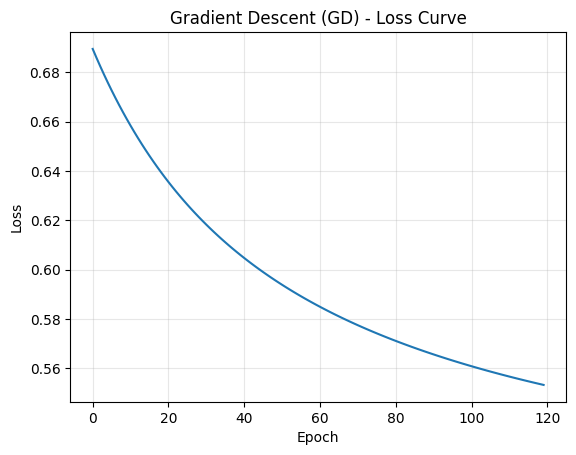

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

X, y = make_classification(
    n_samples=4000, n_features=12, n_informative=8, n_redundant=2, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def bce_loss(y_true, y_prob):
    y_prob = np.clip(y_prob, 1e-12, 1.0 - 1e-12)
    return -np.mean(y_true * np.log(y_prob) + (1.0 - y_true) * np.log(1.0 - y_prob))

w = np.zeros(X_train.shape[1])
b = 0.0
lr = 0.05
epochs = 120
losses = []

t0 = time.perf_counter()
for _ in range(epochs):
    preds = sigmoid(X_train @ w + b)
    err = preds - y_train
    dw = (X_train.T @ err) / len(y_train)
    db = np.mean(err)
    w -= lr * dw
    b -= lr * db
    losses.append(bce_loss(y_train, sigmoid(X_train @ w + b)))
train_time = time.perf_counter() - t0

test_preds = (sigmoid(X_test @ w + b) >= 0.5).astype(int)
print(f"Train Time: {train_time:.4f}s | Final Loss: {losses[-1]:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, test_preds):.4f} | Test F1: {f1_score(y_test, test_preds):.4f}")

plt.plot(losses)
plt.title("Gradient Descent (GD) - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.show()